# EDA, limpieza y armonización — World Happiness 2015-2019
**Workshop 3 · ETL (G01)** — Partes A·1, A·2 y A·3 del enunciado.

Objetivo: perfilar los 5 CSV (nulos, duplicados, nombres de columnas, tipos, diferencias de esquema, outliers), proponer un esquema unificado y justificar cada decisión de limpieza.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src import cleaning as cl
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
raw = {y: pd.read_csv(cl.RAW_DIR / f'{y}.csv') for y in cl.YEARS}

## 1. Perfilado inicial por archivo

In [2]:
resumen = pd.DataFrame({
    y: {'filas': len(d), 'columnas': d.shape[1],
        'nulos (NaN)': int(d.isna().sum().sum()),
        'filas duplicadas': int(d.duplicated().sum()),
        'países duplicados': int(d[[c for c in d.columns if c.lower().startswith('country')][0]].duplicated().sum())}
    for y, d in raw.items()}).T
resumen

,filas,columnas,nulos (NaN),filas duplicadas,países duplicados
2015,158,12,0,0,0
2016,157,13,0,0,0
2017,155,12,0,0,0
2018,156,9,1,0,0
2019,156,9,0,0,0


**Observación:** no hay duplicados ni `NaN` explícitos, pero esto es engañoso: el nulo está escrito como texto `N/A` y hace que pandas lea la columna como `object`. Se revisa a continuación.

## 2. Inconsistencias de nombres y tipos de columnas

In [3]:
filas = []
for y, d in raw.items():
    for c in d.columns:
        filas.append({'año': y, 'columna': c, 'dtype': str(d[c].dtype)})
cols = pd.DataFrame(filas)
cols.pivot_table(index='columna', columns='año', values='dtype', aggfunc='first').fillna('—')

año,2015,2016,2017,2018,2019
columna,,,,,
Country,str,str,str,—,—
Country or region,—,—,—,str,str
Dystopia Residual,float64,float64,—,—,—
Dystopia.Residual,—,—,float64,—,—
Economy (GDP per Capita),float64,float64,—,—,—
Economy..GDP.per.Capita.,—,—,float64,—,—
Family,float64,float64,float64,—,—
Freedom,float64,float64,float64,—,—
Freedom to make life choices,—,—,—,float64,float64


In [4]:
# Columnas que aparecen en cada año
presencia = pd.DataFrame({y: pd.Series(1, index=d.columns) for y, d in raw.items()}).fillna(0).astype(int)
presencia

,2015,2016,2017,2018,2019
Country,1,1,1,0,0
Country or region,0,0,0,1,1
Dystopia Residual,1,1,0,0,0
Dystopia.Residual,0,0,1,0,0
Economy (GDP per Capita),1,1,0,0,0
Economy..GDP.per.Capita.,0,0,1,0,0
Family,1,1,1,0,0
Freedom,1,1,1,0,0
Freedom to make life choices,0,0,0,1,1
GDP per capita,0,0,0,1,1


In [5]:
# Columnas no numéricas que deberían serlo
for y, d in raw.items():
    for c in d.select_dtypes('object').columns:
        if c not in ('Country', 'Region', 'Country or region'):
            print(y, c, d[c][pd.to_numeric(d[c], errors='coerce').isna()].tolist())

/var/folders/v0/9vqs5djn339fhx4wbkkbw15w0000gn/T/ipykernel_44505/1992548916.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in d.select_dtypes('object').columns:
/var/folders/v0/9vqs5djn339fhx4wbkkbw15w0000gn/T/ipykernel_44505/1992548916.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.o

**Hallazgos de esquema**
- 2015/2016: `Country`, `Region`, `Happiness Score`, `Economy (GDP per Capita)`, `Trust (Government Corruption)`…
- 2017: mismos conceptos pero con puntos (`Economy..GDP.per.Capita.`), sin `Region`, floats con ~15 decimales y distinto orden de columnas.
- 2018/2019: nombres nuevos (`Country or region`, `Score`, `Social support`, `Healthy life expectancy`, `Perceptions of corruption`), sin `Region` ni Dystopia.
- `Family` (2015-17) y `Social support` (2018-19) miden lo mismo; igual `Trust` y `Perceptions of corruption`.
- Solo las 6 variables explicativas del contrato + el puntaje existen en los 5 años → ese es el esquema común.
- `Region`, errores estándar, intervalos de confianza, *whiskers* y `Dystopia Residual` no existen en todos los años; además `Dystopia Residual` es **target leakage** (el puntaje es la suma de los 6 componentes + ese residual).

## 3. Valores faltantes reales

In [6]:
d18 = raw[2018]
print(d18[d18['Perceptions of corruption'].astype(str).str.upper().isin(['N/A', 'NAN', ''])].to_string())

Empty DataFrame
Columns: [Overall rank, Country or region, Score, GDP per capita, Social support, Healthy life expectancy, Freedom to make life choices, Generosity, Perceptions of corruption]
Index: []


**Decisión:** el único faltante es *United Arab Emirates 2018* (`corruption = "N/A"`). Se convierte a `NaN` y se **imputa con la mediana de `corruption` de ese mismo año** (robusta a outliers y respeta el nivel del año). Se conserva la fila para no perder un país y se agrega la bandera `corruption_imputed` para trazabilidad.

## 4. Nombres de países inconsistentes entre años

In [7]:
col = {y: [c for c in d.columns if c.lower().startswith('country')][0] for y, d in raw.items()}
paises = {y: set(d[col[y]].str.strip()) for y, d in raw.items()}
comunes = set.intersection(*paises.values())
print('países en total:', len(set.union(*paises.values())), '| en los 5 años:', len(comunes))
for y, s in paises.items():
    print(y, sorted(s - comunes))

países en total: 170 | en los 5 años: 141
2015 ['Angola', 'Central African Republic', 'Comoros', 'Djibouti', 'Hong Kong', 'Laos', 'Lesotho', 'Macedonia', 'Mozambique', 'North Cyprus', 'Oman', 'Somaliland region', 'Sudan', 'Suriname', 'Swaziland', 'Taiwan', 'Trinidad and Tobago']
2016 ['Angola', 'Belize', 'Comoros', 'Hong Kong', 'Laos', 'Macedonia', 'Namibia', 'North Cyprus', 'Puerto Rico', 'Somalia', 'Somaliland Region', 'South Sudan', 'Sudan', 'Suriname', 'Taiwan', 'Trinidad and Tobago']
2017 ['Angola', 'Belize', 'Central African Republic', 'Hong Kong S.A.R., China', 'Lesotho', 'Macedonia', 'Mozambique', 'Namibia', 'North Cyprus', 'Somalia', 'South Sudan', 'Sudan', 'Taiwan Province of China', 'Trinidad and Tobago']
2018 ['Angola', 'Belize', 'Central African Republic', 'Hong Kong', 'Laos', 'Lesotho', 'Macedonia', 'Mozambique', 'Namibia', 'Northern Cyprus', 'Somalia', 'South Sudan', 'Sudan', 'Taiwan', 'Trinidad & Tobago']
2019 ['Central African Republic', 'Comoros', 'Gambia', 'Hong Kong

Varios son el **mismo país con otro nombre** (`Hong Kong` / `Hong Kong S.A.R., China`, `North Cyprus` / `Northern Cyprus`, `Macedonia` / `North Macedonia`, `Somaliland region` / `Somaliland Region`, `Taiwan Province of China` / `Taiwan`, `Trinidad & Tobago` / `Trinidad and Tobago`). Se unifican con la tabla `COUNTRY_ALIASES` de `src/cleaning.py`, que define el nombre canónico. El resto (Angola, Belize, Somalia…) sí son países que entran o salen del ranking según el año y **no** se inventan.

## 5. Outliers potenciales (IQR 1.5)

In [8]:
bruto = cl.clean()
vars_ = cl.FEATURES + [cl.TARGET]
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
pd.DataFrame({'outliers IQR': {v: iqr_out(bruto[v]) for v in vars_}, 'min': bruto[vars_].min(), 'max': bruto[vars_].max()})

,outliers IQR,min,max
gdp,0,0.000,2.09600
family,10,0.000,1.64400
health,0,0.000,1.14100
freedom,0,0.000,0.72400
generosity,17,0.000,0.83808
corruption,68,0.000,0.55191
happiness_score,0,2.693,7.76900


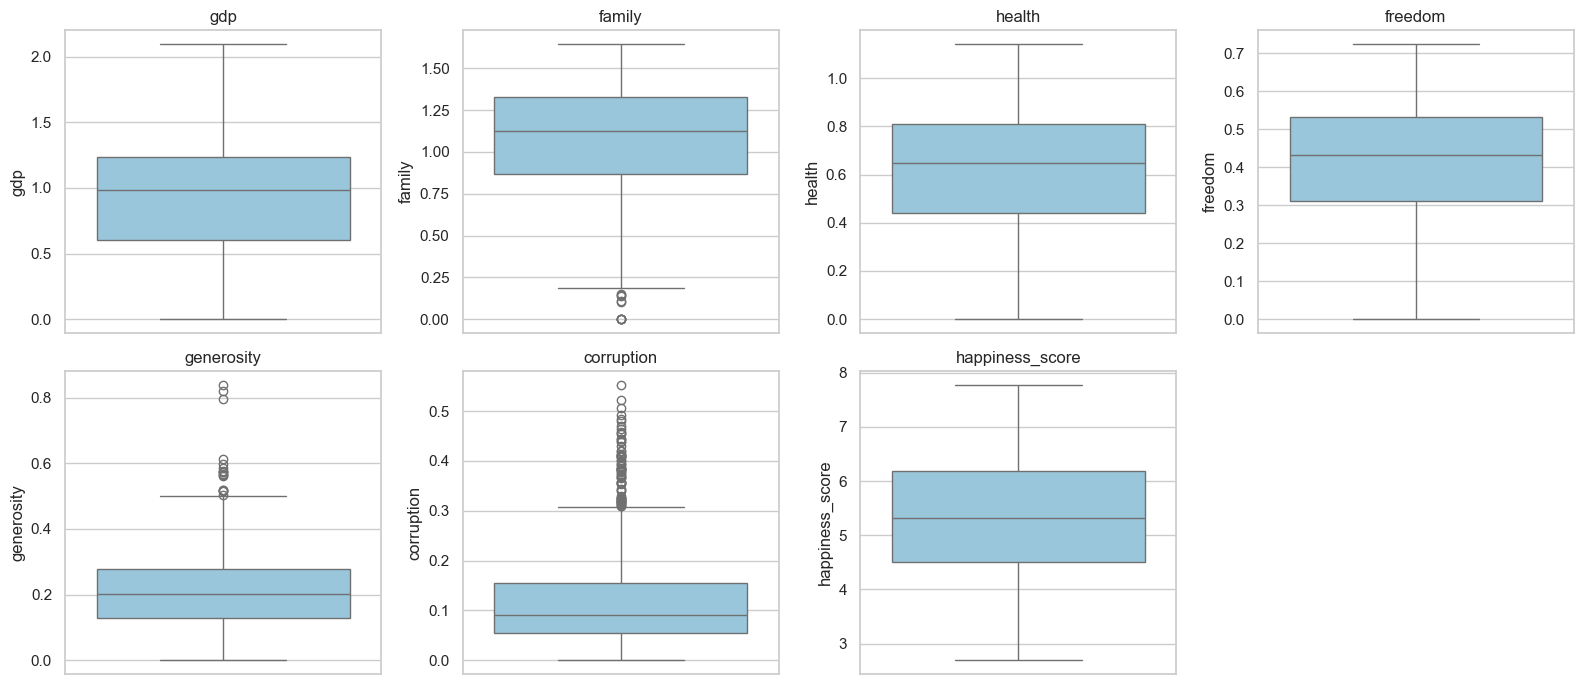

In [9]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, v in zip(ax.ravel(), vars_):
    sns.boxplot(y=bruto[v], ax=a, color='#8ecae6'); a.set_title(v)
ax.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()

In [10]:
# ¿Hay valores en 0 sospechosos (indicadores en 0 exacto)?
(bruto[cl.FEATURES] == 0).sum()

gdp           5
family        5
health        5
freedom       5
generosity    5
corruption    6
dtype: int64

**Decisión:** los outliers de `corruption` (68) y `generosity` (17) son cola derecha legítima; los de `family` (10) son cola izquierda (países en crisis). Son valores publicados por la fuente, no errores de captura, así que **se conservan**: el enunciado pide un modelo simple y borrarlos eliminaría países reales. Los 6 ceros exactos por variable (p. ej. `gdp` = 0 en Somalia, `health` = 0 en Sierra Leona, `generosity` = 0 en Grecia) también se conservan por la misma razón. Todas las variables están en un rango plausible (0–2.1) y no hay valores negativos.

## 6. Esquema unificado propuesto

In [11]:
pd.DataFrame({
  'columna': cl.FINAL_COLUMNS,
  'tipo': ['string','int','float64','float64','float64','float64','float64','float64','float64','bool'],
  'descripción': ['país (nombre canónico)','año del reporte','PIB per cápita','apoyo social / familia','esperanza de vida saludable',
                  'libertad para decidir','generosidad','percepción de corrupción','puntaje de felicidad (target)','corruption imputada']})

,columna,tipo,descripción
0,country,string,país (nombre canónico)
1,year,int,año del reporte
2,gdp,float64,PIB per cápita
3,family,float64,apoyo social / familia
4,health,float64,esperanza de vida saludable
5,freedom,float64,libertad para decidir
6,generosity,float64,generosidad
7,corruption,float64,percepción de corrupción
8,happiness_score,float64,puntaje de felicidad (target)
9,corruption_imputed,bool,corruption imputada


## 7. Limpieza + integración → dataset unificado

In [12]:
df = cl.clean()
out = cl.RAW_DIR.parent / 'processed' / 'happiness_clean.csv'
df.to_csv(out, index=False)
print(df.shape, '->', out.name)
print(df.dtypes)
df.groupby('year').size()

(782, 10) -> happiness_clean.csv
country                string
year                    int64
gdp                   float64
family                float64
health                float64
freedom               float64
generosity            float64
corruption            float64
happiness_score       float64
corruption_imputed       bool
dtype: object


year
2015    158
2016    157
2017    155
2018    156
2019    156
dtype: int64

In [13]:
# Controles de calidad posteriores a la limpieza
assert df.isna().sum().sum() == 0
assert not df.duplicated(['country', 'year']).any()
assert df[cl.FEATURES + [cl.TARGET]].apply(lambda s: s.between(0, 8)).all().all()
print('OK: sin nulos, sin duplicados (país, año) y valores en rango')

OK: sin nulos, sin duplicados (país, año) y valores en rango


## 8. Feature engineering (Parte A·3)
### Estadísticas descriptivas y relaciones

In [14]:
df[cl.FEATURES + [cl.TARGET]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
gdp,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096
family,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644
health,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838
corruption,782.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552
happiness_score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769


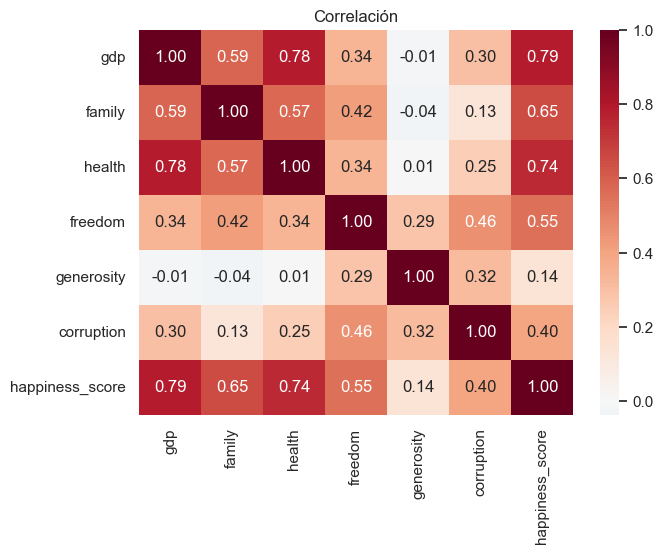

gdp           0.789
health        0.742
family        0.649
freedom       0.551
corruption    0.397
generosity    0.138
Name: happiness_score, dtype: float64

In [15]:
corr = df[cl.FEATURES + [cl.TARGET]].corr()
plt.figure(figsize=(7, 5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0); plt.title('Correlación'); plt.show()
corr[cl.TARGET].drop(cl.TARGET).sort_values(ascending=False).round(3)

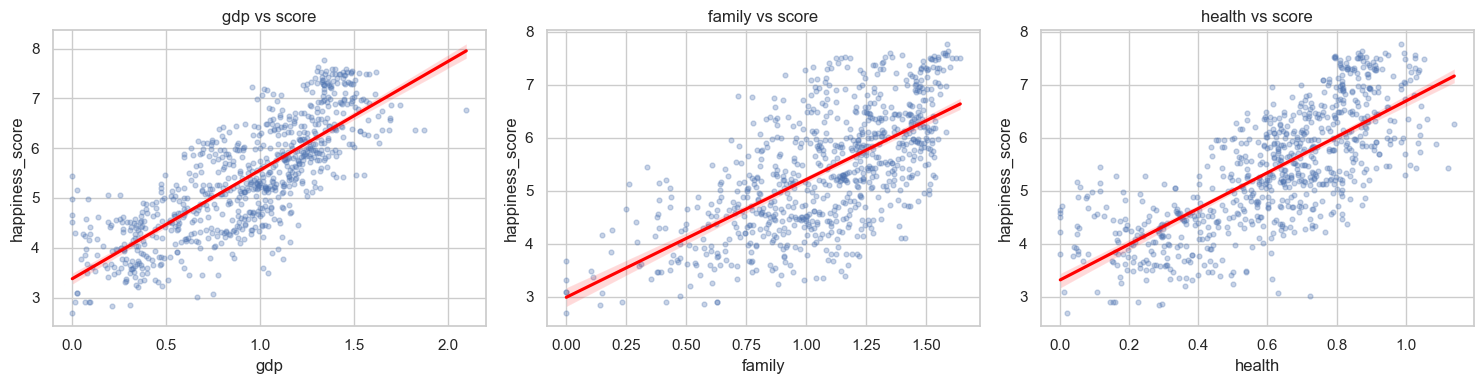

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, ['gdp', 'family', 'health']):
    sns.regplot(data=df, x=v, y=cl.TARGET, ax=a, scatter_kws={'alpha': .3, 's': 12}, line_kws={'color': 'red'}); a.set_title(f'{v} vs score')
plt.tight_layout(); plt.show()

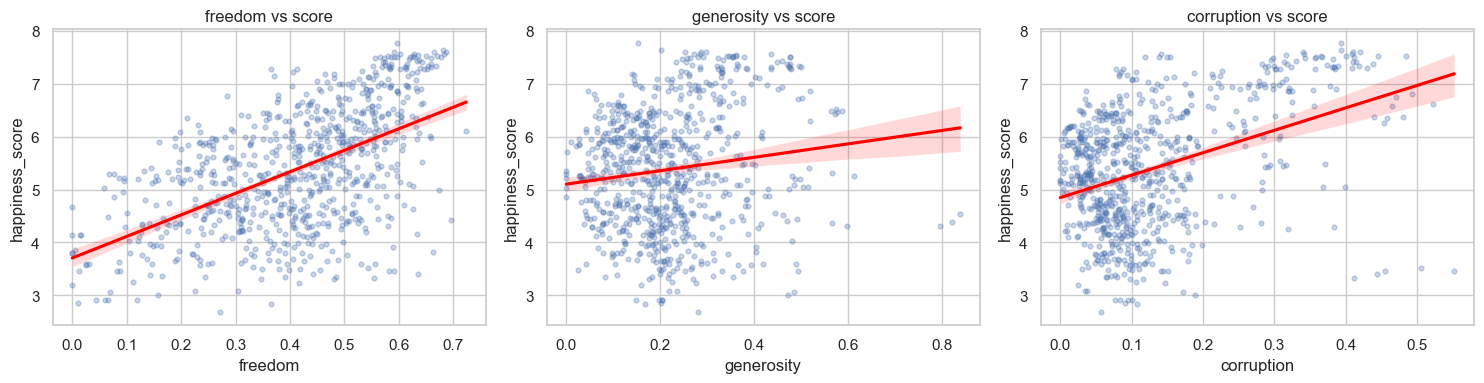

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, ['freedom', 'generosity', 'corruption']):
    sns.regplot(data=df, x=v, y=cl.TARGET, ax=a, scatter_kws={'alpha': .3, 's': 12}, line_kws={'color': 'red'}); a.set_title(f'{v} vs score')
plt.tight_layout(); plt.show()

### Selección de features y justificación
| Feature | Decisión | Justificación |
|---|---|---|
| `gdp`, `family`, `health` | ✅ usar | Correlación alta con el puntaje; presentes en los 5 años |
| `freedom` | ✅ usar | Correlación moderada, aporta información distinta |
| `corruption` | ✅ usar | Correlación moderada-baja pero forma parte del contrato de eventos |
| `generosity` | ✅ usar | Débil; se mantiene porque el contrato la exige y es inocua para un modelo lineal |
| `happiness_score` | ❌ **target** | Solo se usa como etiqueta y para calcular el error |
| `Dystopia Residual` | ❌ leakage | Se calcula a partir del propio puntaje |
| `Standard Error`, intervalos, *whiskers* | ❌ | Derivados del puntaje; no existen en todos los años |
| `Region` | ❌ | Solo 2015-16 y no está en el contrato de evento |
| `year` | ❌ | No es feature del contrato; solo identifica la observación y alimenta `dim_date` |
| `corruption_imputed` | ❌ | 1 solo caso; no se envía por el evento |

**Categóricas:** ninguna feature es categórica, así que no se usa *encoding*. **Escalado:** se aplica `StandardScaler` dentro del `Pipeline` (aprendido solo con el conjunto de entrenamiento) para que el preprocesamiento viaje serializado junto con el modelo.